## TAREA 2 MACHINE LEARNING: LOS TERREMOTOS

### **FABIÁN CARVAJAL Y BASTIÁN PAREDES**

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Construcción de un modelo

#### I. 
Se quiere predecir la magnitud del sismo segun la profundidad y su ubicación.
1. ¿Qué variable intentarán predecir (target)?

 Clasificación binaria de la magnitud en ‘fuerte’ o ‘débil’

2. ¿Que variables utilizaran como entrada (features)?

Se utilizarán las variables Depth, profundiad del sismo en kilómetros y Place, lugar del sismo, ya sea ciudad y/o país.

3. ¿Se trata de un problema de clasificación o regresión?

Es un problema de clasificación 

4. ¿Por qué consideran que los datos disponibles podrían contener información
útil para realizar esta predicción?

En la tarea anterior vimos que a mayor profundidad, la magnitud máxima que puede tener un sismo tiende a bajar, aunque dentro de ese rango sigue habiendo harta variedad. También vimos que el lugar influye en qué tan profundos pueden ser los sismos de esa zona. Por esto, se espera que depth y lat/long puedan aportar información útil para distinguir entre sismos fuertes y débiles.

#### II. 

Para este problema se usará un árbol de decisión ya que es útil en problemas de clasificación, maneja bien relaciones no lineales y es más simple de interpretar que otros modelos. Esto es importante porque en la Tarea 1 vimos que la relación entre profundidad y magnitud no es lineal, por lo que un modelo como regresión logística podría no capturar bien esa relación. Además, al ser un modelo fácil de interpretar, permite revisar en qué valores de depth, lat o long el árbol decide separar entre sismos fuertes y débiles, lo cual ayuda a entender mejor su comportamiento.

### III.

In [28]:
df = pd.read_csv("earthquakes_usgs.csv")

df_modelo = df.dropna(subset=['depth', 'latitude', 'longitude', 'mag']).copy()

df_modelo['clase'] = (df_modelo['mag'] >= 6.0).astype(int)

X = df_modelo[['depth', 'latitude', 'longitude']]
y = df_modelo['clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X_train, y_train)

y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

print("Accuracy train:", accuracy_score(y_train, y_pred_train))
print("Accuracy test:", accuracy_score(y_test, y_pred_test))

print(classification_report(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))

Accuracy train: 0.999991930472955
Accuracy test: 0.9236306123107711
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     59085
           1       0.20      0.21      0.20      2877

    accuracy                           0.92     61962
   macro avg       0.58      0.58      0.58     61962
weighted avg       0.93      0.92      0.92     61962

[[56631  2454]
 [ 2278   599]]


In [29]:
print(df_modelo['clase'].value_counts())

clase
0    295423
1     14385
Name: count, dtype: int64


In [34]:
razon_clases = round((14385/295423)*100,2)
print('Razon entre clases: {}%'.format(razon_clases))

Razon entre clases: 4.87%


#### IV.

Para evaluar el modelo no basta con mirar el accuracy, ya que las clases están muy desbalanceadas (solo el 4.87% de los sismos son "fuertes"). Un modelo que prediga siempre "débil" ya tendría un accuracy cercano a 0.95 sin haber aprendido nada útil.

Por esto, se decidió evaluar principalmente con recall y precision de la clase "fuerte". El recall indica qué porcentaje de los sismos fuertes reales el modelo logra detectar, mientras que la precision indica qué tan confiable es el modelo cuando predice que un sismo es fuerte. Dado que en una aplicación real sería más grave no detectar un sismo fuerte que generar una falsa alarma, se prioriza el recall de esta clase por sobre la precision o el accuracy global.

El modelo obtuvo un accuracy de 0.9999 en entrenamiento y 0.9236 en test, lo que ya muestra una diferencia importante entre ambos conjuntos. Sin embargo, al mirar la clase "fuerte" en test, el recall fue de solo 0.21 y la precision de 0.20, bastante bajos. Esto indica que, a pesar del accuracy alto, el modelo no está logrando distinguir bien los sismos fuertes de los débiles, y que ese accuracy está dominado por el buen desempeño en la clase mayoritaria.

# Un experimento con el modelo

### Prediccion: 
Al limitar la profundidad del árbol, se evitara un sobreajuste extremo en los datos, se obliga al modelo a generalizar más que aprender de memoria. Pero esto a su vez, disminuye los valores de las métricas, ami parecer la más afectada sería el recall, el modelo clasificará peor los sismos de magnitudes altas.

### Experimentación:

Si solo le ponemos un limite a la profundiad del arbol (igual a 5) se tiene lo siguiente:

In [42]:
df = pd.read_csv("earthquakes_usgs.csv")
df_modelo = df.dropna(subset=['depth', 'latitude', 'longitude', 'mag']).copy()

df_modelo['clase'] = (df_modelo['mag'] >= 6.0).astype(int)

print(df_modelo['clase'].value_counts())

X = df_modelo[['depth', 'latitude', 'longitude']]
y = df_modelo['clase']

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo_2 = DecisionTreeClassifier(max_depth = 5, random_state=42)
modelo_2.fit(X_train_2, y_train_2)

y_pred_train = modelo_2.predict(X_train_2)
y_pred_test = modelo_2.predict(X_test_2)

print("Accuracy train:", accuracy_score(y_train_2, y_pred_train))
print("Accuracy test:", accuracy_score(y_test_2, y_pred_test))

print(classification_report(y_test_2, y_pred_test))
print(confusion_matrix(y_test_2, y_pred_test))

clase
0    295423
1     14385
Name: count, dtype: int64
Accuracy train: 0.953571976146478
Accuracy test: 0.9535683160646848
              precision    recall  f1-score   support

           0       0.95      1.00      0.98     59085
           1       0.00      0.00      0.00      2877

    accuracy                           0.95     61962
   macro avg       0.48      0.50      0.49     61962
weighted avg       0.91      0.95      0.93     61962

[[59085     0]
 [ 2877     0]]


/Users/bastianparedes/ML/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bastianparedes/ML/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bastianparedes/ML/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Luego se añade class_weight = 'balanced' para que el modelo tome en cuenta el desbalance del set de datos. Les da menos pesos a los sismos débiles ya que son mas comunes y les da mas peso a los fuertes. 

In [47]:
df = pd.read_csv("earthquakes_usgs.csv")
df_modelo = df.dropna(subset=['depth', 'latitude', 'longitude', 'mag']).copy()

df_modelo['clase'] = (df_modelo['mag'] >= 6.0).astype(int)

print(df_modelo['clase'].value_counts())

X = df_modelo[['depth', 'latitude', 'longitude']]
y = df_modelo['clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo = DecisionTreeClassifier(max_depth = 5, random_state=42, class_weight= 'balanced')
modelo.fit(X_train, y_train)

y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

print("Accuracy train:", accuracy_score(y_train, y_pred_train))
print("Accuracy test:", accuracy_score(y_test, y_pred_test))

print(classification_report(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))

clase
0    295423
1     14385
Name: count, dtype: int64
Accuracy train: 0.8032366872977574
Accuracy test: 0.8021206545947516
              precision    recall  f1-score   support

           0       0.97      0.81      0.89     59085
           1       0.13      0.55      0.20      2877

    accuracy                           0.80     61962
   macro avg       0.55      0.68      0.55     61962
weighted avg       0.93      0.80      0.86     61962

[[48122 10963]
 [ 1298  1579]]


Podemos ver como evolucionan estas métricas cuando se cambia la profundidad del árbol para poder elegir la mas conveniente. 

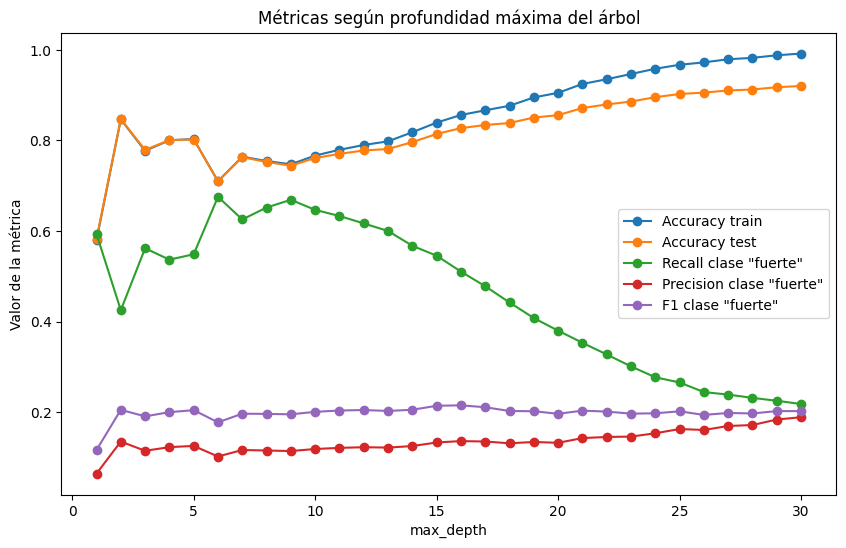

In [23]:
from sklearn.metrics import recall_score, precision_score, f1_score

profundidades = range(1, 31)

train_acc = []
test_acc = []
test_recall_clase1 = []
test_precision_clase1 = []
test_f1_clase1 = []

for d in profundidades:
    modelo_d = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight= 'balanced')
    modelo_d.fit(X_train_2, y_train_2)
    
    pred_train = modelo_d.predict(X_train_2)
    pred_test = modelo_d.predict(X_test_2)
    
    train_acc.append(accuracy_score(y_train_2, pred_train))
    test_acc.append(accuracy_score(y_test_2, pred_test))
    test_recall_clase1.append(recall_score(y_test_2, pred_test, pos_label=1))
    test_precision_clase1.append(precision_score(y_test_2, pred_test, pos_label=1, zero_division=0))
    test_f1_clase1.append(f1_score(y_test_2, pred_test, pos_label=1, zero_division=0))

plt.figure(figsize=(10,6))
plt.plot(profundidades, train_acc, label='Accuracy train', marker='o')
plt.plot(profundidades, test_acc, label='Accuracy test', marker='o')
plt.plot(profundidades, test_recall_clase1, label='Recall clase "fuerte"', marker='o')
plt.plot(profundidades, test_precision_clase1, label='Precision clase "fuerte"', marker='o')
plt.plot(profundidades, test_f1_clase1, label='F1 clase "fuerte"', marker='o')
plt.xlabel('max_depth')
plt.ylabel('Valor de la métrica')
plt.title('Métricas según profundidad máxima del árbol')
plt.legend()

Se puede observar que con un max_depth = 9 se llega a un pundo de equilibrio entre los accuracy para el entrenamiento y el test y con el recall para la clase fuerte. Para esta clase la precision y F1 se mantienen abajo para cualquier profundidad. 

In [48]:
df = pd.read_csv("earthquakes_usgs.csv")
df_modelo = df.dropna(subset=['depth', 'latitude', 'longitude', 'mag']).copy()

df_modelo['clase'] = (df_modelo['mag'] >= 6.0).astype(int)

print(df_modelo['clase'].value_counts())

X = df_modelo[['depth', 'latitude', 'longitude']]
y = df_modelo['clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo = DecisionTreeClassifier(max_depth = 9, random_state=42, class_weight= 'balanced')
modelo.fit(X_train, y_train)

y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

print("Accuracy train:", accuracy_score(y_train, y_pred_train))
print("Accuracy test:", accuracy_score(y_test, y_pred_test))

print(classification_report(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))

clase
0    295423
1     14385
Name: count, dtype: int64
Accuracy train: 0.7474802901801926
Accuracy test: 0.7444724185791292
              precision    recall  f1-score   support

           0       0.98      0.75      0.85     59085
           1       0.11      0.67      0.20      2877

    accuracy                           0.74     61962
   macro avg       0.55      0.71      0.52     61962
weighted avg       0.94      0.74      0.82     61962

[[44204 14881]
 [  952  1925]]


Resumiendo datos importantes en una tabla se tiene: 

In [40]:
import pandas as pd

resultados = pd.DataFrame({
    'Modelo': ['Original (sin límite)', 'max_depth=5 (sin class_weight)', 'max_depth=9 + class_weight'],
    'Accuracy train': [0.9999, 0.9536, 0.7475],
    'Accuracy test': [0.9236, 0.9536, 0.7445],
    'Recall clase "fuerte"': [0.21, 0.00, 0.67],
    'Precision clase "fuerte"': [0.20, 0.00, 0.11],
    'F1 clase "fuerte"': [0.20, 0.00, 0.20]
})

resultados

resultados

,Modelo,Accuracy train,Accuracy test,"Recall clase ""fuerte""","Precision clase ""fuerte""","F1 clase ""fuerte"""
0,Original (sin límite),0.9999,0.9236,0.21,0.20,0.2
1,max_depth=5 (sin class_weight),0.9536,0.9536,0.00,0.00,0.0
2,max_depth=9 + class_weight,0.7475,0.7445,0.67,0.11,0.2


### Interpretacion: 
La predicción fue acertada tanto en la desaparicion del overfitting y la disminucion en el recall. También se puede ver que los modelos 0 y 1 muestran un Accuracy superior a $92%$ pero son pésimos identificando sismos fuertes. El Modelo 2 es el mejor balance operativo, en sismología o gestión de riesgos, es preferible tener falsos positivos (alertar sobre un sismo que termina siendo moderado) antes que tener falsos negativos (no detectar un sismo de gran magnitud).

# Auditoría del modelo

1. El modelo base presenta un Accuracy train de $0.9999$ frente a un Accuracy test de $0.9236$. Esto prueba que la brecha entre entrenamiento y prueba muestra que el árbol memorizó el ruido y las coordenadas específicas del dataset. Además, el modelo no generaliza para la clase crítica, alcanzando solo un $0.21$ de Recall en prueba. En el modelo 1 se tiene que Accuracy train y Accuracy test se igualan en $0.9536$, pero Recall, Precision y F1-score caen a $0.00$ para sismos fuertes, lo que se traduce en que el modelo clasifica todo como "baja/moderada intensidad" e ignora por completo los eventos de mayor magnitud. El último modelo presenta un Accuracy train de $0.7475$ y Accuracy test de $0.7445$, con un Recall de $0.67$ en la clase fuerte. Es el único modelo con un ajuste adecuado (sin sobreajuste ni subajuste crítico). La convergencia casi exacta entre entrenamiento y prueba demuestra que el modelo generaliza patrones espaciales/profundos reales en lugar de memorizar datos.

2. Hay presencia de falsos negativos, al limitar la profundidad (max_depth=5), el árbol crea regiones geográficas muy amplias. Si un sismo fuerte ocurre en una zona donde predominan los eventos pequeños, la regla del nodo lo clasifica por mayoría como "Baja Intensidad". Tambien, se encuentran los falsos positivos en el modelo con class_weight, el peso asignado a la clase fuerte vuelve al árbol muy "conservador". En zonas de alta sismicidad (como Chile o Japón), marca franjas completas como de alto riesgo, clasificando eventos menores como fuertes. Ambos casos son causados porque los árboles dividen el espacio mediante rectángulos rígidos (latitud y longitud). Como los límites de las placas tectónicas son curvos o diagonales, el modelo falla sistemáticamente en los bordes al intentar aproximar curvas con cortes rectangulares.

3. Por un lado un Accuracy global elevado ($\sim 95\%$) no garantiza que el modelo sea útil. En datasets desbalanceados, el modelo puede alcanzar esa cifra ignorando completamente la clase de interés ($0\%$ de Recall en sismos fuertes).  Por su parte mejorar la detección de sismos de gran magnitud (de $21\%$ a $55\%$) requiere asumir un impacto negativo en la Precisión ($13\%$). En otras palabras, para no perder terremotos reales, el modelo debe generar muchas detecciones de falsas alarmas en zonas de alta sismicidad.


4.  Los árboles de decisión dividen el espacio en rectángulos rígidos, lo que causa errores en los bordes diagonales/curvos de las fallas tectónicas. El kernel RBF de SVM crea fronteras de decisión suaves y circulares/curvas basadas en la distancia entre coordenadas, adaptándose de forma natural a las fosas de subducción. Esto generaria una mejor delimitación en las zonas de alto riesgo real en lugar de marcar áreas innecesariamente grandes de territorio, lo que ayudará a elevar la precisión actual del $13\%$ sin sacrificar la detección de eventos fuertes.

# Conclusiones

El modelo no es lo suficientemente confiable para usarse en una aplicación real de detección de sismos fuertes. Si bien se logró reducir el sobreajuste inicial (de un accuracy train de 0.9999 a valores más cercanos entre train y test), ningún modelo logró un buen desempeño simultáneo en accuracy, precision y recall para la clase de interés.

Como fortaleza, el modelo con max_depth=9 y class_weight='balanced' logró un recall de 0.67 en la clase "fuerte", mostrando que sí es posible mejorar bastante la detección de sismos fuertes ajustando cómo el modelo pondera los errores durante el entrenamiento, sin necesitar features adicionales a las tres que se usaron (depth, latitud, longitud).

Como limitación principal, ese mismo modelo tiene una precision de solo 0.11, por lo que genera muchas falsas alarmas: de cada 10 sismos que predice como "fuertes", solo 1 realmente lo es. Esto se debe en parte a que un árbol de decisión divide el espacio en regiones rectangulares, lo que no se ajusta bien a la geometría real de las zonas de subducción (que son curvas o diagonales), generando errores sistemáticos en los bordes de esas zonas.
